## Практическое домашнее задание 2. Градиентный спуск своими руками

### Общая информация

Дата выдачи: 16.10.2026

Мягкий дедлайн: 16.11.2026 23:59 MSK

Жесткий дедлайн: 23.11.2026 23:59 MSK


### Оценивание и штрафы

Каждая из задач имеет определенную «стоимость» (указана в скобках около задачи). **Максимально допустимая оценка за работу — 10 баллов.**

Задание выполняется самостоятельно. «Похожие» решения считаются плагиатом и все задействованные студенты (в том числе те, у кого списали) не могут получить за него больше 0 баллов (подробнее о плагиате см. на странице курса). Если вы нашли решение какого-то из заданий (или его часть) в открытом источнике, необходимо указать ссылку на этот источник (скорее всего вы будете не единственным, кто это нашел, поэтому чтобы исключить подозрение в плагиате, необходима ссылка на источник).

Неэффективная реализация кода может негативно отразиться на оценке. Также оценка может быть снижена за плохо читаемый код и плохо считываемые диаграммы.

Все ответы должны сопровождаться кодом или комментариями о том, как они были получены.

Для удобства проверки самостоятельно посчитайте свою максимальную оценку (исходя из набора решенных задач) и укажите ниже.

**Оценка**: 9,5


### О задании

В данном задании необходимо реализовать обучение линейной регрессии с помощью различных модификаций градиентного спуска. В файле `descents.py` вам нужно будет реализовать несколько классов для различных вариаций градиентного спуска, а именно:
* `VanillaGradientDescent`
* `StochasticGradientDescent`
* `SAGDescent`
* `MomentumDescent`
* `Adam`


В файле `linear_regression.py` вам необходимо будет реализовать класс `CustomLinearRegression` для обучения линейной регрессии (и, разумеется, предсказания целевой переменной на основе обученной модели).


### Про предложенную архитектуру

Предложенная вам архитектура шаблонов написана по принципам SOLID: основная ее идея в том, что вы сможете использовать различные лоссы и оптимизаторы с одним и тем же кодом прочих классов, никак не изменяя и не переписывая методы классов, которые с оптимизаторами и лоссом взаимодействуют. Мы добиваемся этого при помощи выделения интерфейсов (в Python мы достигаем этого при помощи абстрактных классов, см дальше в заданиях) и выделения зон ответственности каждого класса.

Глобально в нашей архитектуре всего 4 интерфейса (некоторые из которых на самом деле сразу concrete классы), каждый из которых порождает одно семейство:
- `interfaces.LossFunction`
  - Классы, имплементирующие этот интерфейс, отвечают за одну конкретную функцию потерь, используемую при обучении, и всё, что меняется вместе с ней при её замене: подсчёт лосса, подсчет градиента и аналитическое решение (если есть, то добавляется в интерфейс соответствующим mixin-ом).
- `interfaces.LinearRegressionInterface`
  - Интерфейс обертки для модели линейной регрессии, контейнер, содержащий составные части (лосс-функцию и оптимизатор) и использующий их для выполнения содержательной работы.
- `interfaces.LearningRateSchedule`
 - Простенькое семейство расписаний, определяющих шаг обучения для каждой итерации
- `interfaces.AbstractOptimizer`.
  -  Классы, имплементирующие этот интерфейс, имплементируют конкретный алгоритм оптимизации и всё, что происходит в его процессе. Пользуются обёрткой линейной регрессии для доступа к данным и вызова расчетов, чтобы не зависеть напрямую от конкретных функций потерь и шедулеров шага обучения.

Концепция передачи маленьких объектов, отвечающих за свою маленькую зону ответственности внутрь более сложного объекта для выполнения ими составных частей работы называется Dependency Injection, и работает как раз за счет выделения зоны ответственности и опоры на интерфейс вместо реализации.

Посмотрите на код `linear_regression.CustomLinearRegression`: она принимает в себя объекты с интерфейсами `LossFunction` и `AbstractOptimizer`, а в `descents.BaseDescent` как уточнении интерфейса абстрактного оптимизатора до итеративных оптимизаторов видно, что он в свою очередь принимает при инициализации объект шедулера шага обучения.

Благодаря этому, код, который использует эти классы, может по очереди:
- Инициализировать нужный шедулер с нужными параметрами для задания шага обучения
- Иницализировать оптимизатор, задав ему нужные параметры процесса и передав готовый шедулер
- Инициализировать класс линейной регрессии нужной под задачу функцией потерь и уже готовым оптимизатором.
- Запустить процесс обучения

И на любом этапе можно использовать другой объект с подходящим интерфейсом, и всё будет работать!


**В ходе выполнения этой домашки вы наполните все эти семейства классов различными имплементациями и будете менять их на ходу как перчатки!**

Более подробно про наследование классов в Python можно прочитать здесь:
* Наследование: https://docs.python.org/3/tutorial/classes.html#inheritance
* Абстрактные классы: https://docs.python.org/3/library/abc.html



## Задание 1. Линейная регрессия  (1 балл)

### Градиент функции потерь MSE

### Задание 1.0. Градиент MSE в матричном виде (0.3 балла).

Напомним, что функция потерь MSE записывается как:

$$
    Q(w) = \frac{1}{\ell} \sum \limits_{i = 1}^\ell (y_i - \langle x_i, w \rangle)^2 = \frac{1}{\ell} \| X w - y \|^2
$$

где $\ell$ – количество объектов в выборке, $X \in \mathbb{R}^{\ell \times d}$ – матрица "объект-признак", а $y \in \mathbb{R}^\ell$ – целевая переменная. Через $x_i$ обозначается $i$-ая строчка матрицы $X$, отвечающая за $i$-й объект выборки.

- **Выпишите ниже градиент для функции потерь MSE в матричном виде.**

**Решение:**

$$
    \frac{2}{\ell} X^T (Xw - y)
$$


- **Имплементируйте методы `MSELoss.loss`, `MSELoss.gradient`**





### Задание 1.1 Аналитическое решение и `CustomLinearRegression` (0.7 балла)

Перед тем, как мы углубимся в итеративные методы оптимизации, давайте вспомним, что для ряда функций потерь существует и аналитическое решение. Давайте сперва вспомним, как оно выглядит для MSE.

- **Выведите формулу оптимальных $w$ в задаче минимизации MSE, и запишите её ниже.**

- **Имплементируйте подсчет этого решения в `MSELoss._plain_analytic_solution`**

$$\text{MSE} = \| X w - y \|^2$$
$$ w = (X^T X)^{-1} X^T y$$

**Вопрос**: Как мы помним, у аналитического решения есть минусы - какие?

**Ответ**: 
1. **Вычислительная сложность:** Обращение матрицы \((X^T X)\) требует \(O(d^3)\) операций, где d — число признаков. При больших d это работает очень медленно.
2. **Требовательность к памяти:** Необходимо хранить и обрабатывать матрицу \(X^T X\), что при большом количестве признаков может занять много оперативной памяти.
3. **Проблема мультиколлинеарности:** Матрица \((X^T X)\) может быть вырожденной (необратимой), если признаки линейно зависимы. В таком случае классическое решение не существует или становится численно нестабильным.

Теперь прокинем это решение в наш класс линейной регрессии, чтобы получше разобраться в архитектуре.


- **Допишите класс `descents.AnalyticSolutionOptimizer`**
- **Допишите класс `CustomLinearRegression`**
  - В нем на текущем этапе нужно имплементировать все методы: `fit` и `predict` вам понадобятся прямо сейчас, а `compute_gradients` и `compute_loss` в следующей части.

Помните, про разделение ответственности классов!

За контроль процесса обучения отвечает оптимизатор, а объект линейной регрессии по факту выступает точкой входа, контейнером для данных и способом доступа к вычислениям, на основе которых оптимизатор принимает решения (e.g. значение антиградиента в точке весов).

При этом сам по себе оптимизатор должен быть универсален, в нем никак не должны содержаться детали, связанные с конкретными функциями потерь, все необходимое от них он может получить через `self.model`.

Аналогично, класс линейной регрессии тоже должен быть универсальным и готовым к работе с любыми лоссами и оптимизаторами, исполняющими заявленный интерфейс. Здесь применена dependency injection, и вы должны грммотно ее поддержать в своей имплементации. Аналогично, все, что вам может быть нужно от функций потерь, вы можете получить при помощи обращения к переданному объекту.

In [22]:
import numpy as np
from linear_regression import MSELoss, CustomLinearRegression, AnalyticSolutionOptimizer

num_objects = 100
dimension = 5

x = np.random.rand(num_objects, dimension)
y = np.random.rand(num_objects)

In [23]:
from sklearn.metrics import mean_squared_error as mse
import sklearn

sklearn_linreg = sklearn.linear_model.LinearRegression(fit_intercept=False)
sklearn_linreg.fit(x, y)
print("Sklearn MSE", mse(sklearn_linreg.predict(x), y))

your_linreg = CustomLinearRegression(AnalyticSolutionOptimizer(), loss_function=MSELoss())
your_linreg.fit(x, y)
print("Your MSE", mse(your_linreg.predict(x), y))

assert abs(mse(your_linreg.predict(x), y) - mse(sklearn_linreg.predict(x), y)) < 1e-12, "Не повезло, попробуйте еще раз"

Sklearn MSE 0.08965765744541342
Your MSE 0.08965765744541343


Давайте сделаем задание немного прикольнее и изменим одну из колонок. Как мы знаем, полная мультиколлинеарность запрещает нам пользоваться аналитическим решением, но `sklearn` по какой-то причине это обходит, хмм

In [24]:
x[:, 3] = x[:, 2] + x[:, 4]

In [25]:
sklearn_linreg = sklearn.linear_model.LinearRegression(fit_intercept=False)
sklearn_linreg.fit(x, y)
print("Sklearn MSE", mse(sklearn_linreg.predict(x), y))

your_linreg = CustomLinearRegression(AnalyticSolutionOptimizer(), loss_function=MSELoss())
your_linreg.fit(x, y)
print("Your MSE", mse(your_linreg.predict(x), y))

Sklearn MSE 0.09457054286249549
Your MSE 0.09457054286249551


Ваша задача - понять, как можно сделать так, чтобы аналитическое решение работало всегда, вне зависимости от матрицы X. Как оказывается, это можно сделать, если воспользоваться SVD разложением. Для имплементации воспользуйтесь `scipy.sparse.linalg.svds`.

- Выведите через SVD формулу оптимальных $w$ в задаче минимизации MSE.

- Имплементируйте подсчет этого решения в `MSELoss._svd_analytic_solution`
    - Мир итерационных агоритмов причудлив. Если вы посмотрите на опции солверов svds, то увидите, что возможности вычислить точно все сингулярные числа вам не дают (propack рандомизированный и даст вам неточные ответы). Используйте стандартный солвер, выставьте максимальную доступную точность.

- Ответьте на **вопрос на засыпку**. Вообще говоря, в ряде случаев (например в нашем), даже такая неабсолютная на первый взгляд точность все равно позволяет получить точное решение задачи. Обоснуйте, почему? Как называется такой вид SVD? Какого минимального числа сингулярных чисел с вероятностью 1 будет достаточно в нашем случае для получения точного решения? Обоснуйте, почему.


$$\text{X} = \underset{n\times m}{\mathrm{U}} \ \underset{m\times m}{\mathrm{\Sigma}} \ \underset{m\times k}{\mathrm{V^T}}$$
$$ w = V \Sigma^{-1} U^T y $$

**Ответ**: 
1. Алгоритм SVD позволяет найти псевдорешение (решение метода наименьших квадратов минимальной нормы). При мультиколлинеарности матрица X имеет неполный ранг, и часть её сингулярных чисел равна нулю (или очень близка к нулю из-за погрешности вычислений). Мы просто отбрасываем эти нулевые компоненты (заменяем их обратные значения на ноль), что позволяет избежать деления на ноль и получить устойчивое решение.
2. Такой вид называется **Усеченным SVD (Truncated SVD)**. В контексте линейной алгебры и статистики этот подход эквивалентен вычислению через **псевдообратную матрицу Мура-Пенроуза**.
3. В нашем случае один столбец является линейной комбинацией двух других, поэтому ранг матрицы X уменьшается на 1 (с 5 до 4). Следовательно, минимального числа сингулярных чисел, равного **рангу матрицы (4)**, будет достаточно для получения точного решения. Остальные сингулярные числа будут равны нулю.

In [26]:
sklearn_linreg = sklearn.linear_model.LinearRegression(fit_intercept=False)
sklearn_linreg.fit(x, y)
print("Sklearn MSE", mse(sklearn_linreg.predict(x), y))


your_linreg =  CustomLinearRegression(AnalyticSolutionOptimizer(),
                                      loss_function=MSELoss(analytic_solution_func=MSELoss._svd_analytic_solution))
your_linreg.fit(x, y)

print("Your MSE", mse(your_linreg.predict(x), y))

assert abs(mse(your_linreg.predict(x), y) - mse(sklearn_linreg.predict(x), y)) < 1e-12, "Не повезло, попробуйте еще раз"

Sklearn MSE 0.09457054286249549
Your MSE 0.09457054286249549


## Задание 2. Реализация градиентного спуска (4 балла)

В этом задании вам предстоит написать собственные реализации различных подходов к градиентному спуску с опорой на подготовленные шаблоны в файле `descents.py`. При помощи них мы будем искать итеративные решения, подавая оптимизаторы внутрь нашей `CustomLinearRegression`.

### Напоминание про градиентный спуск

Основное свойство антиградиента &ndash; он указывает в сторону *наискорейшего* убывания функции в данной точке. Соответственно, будет логично стартовать из некоторой точки, сдвинуться в сторону антиградиента,
пересчитать антиградиент и снова сдвинуться в его сторону и т.д. Запишем это более формально.

Пусть $w_0$ &ndash; начальный набор параметров (например, нулевой или сгенерированный из некоторого
случайного распределения). Тогда ванильный градиентный спуск состоит в повторении следующих шагов до сходимости:

$$
    w_{k + 1} = w_{k} - \eta_{k} \nabla_{w} Q(w_{k}).
$$

Здесь $\eta_{k}$ обозначает длину шага на $k$-ой итерации (learning rate), а $Q(w)$ - функцию потерь (loss function).

Градиент для MSE вы уже нашли выше

### Задание 2.0. Learning Rate Schedules (0.2 балла)

Обратите внимание на **абстрактный** класс `LearningRateSchedule` в файле `descents.py`. С помощью его имплементаций мы на каждой итерации градиентного спуска будем получать соответствующий `learning_rate` $\eta_k$.

В файле уже реализован класс `ConstantLR`, который на каждой итерации возвращает один и тот же заранее заданный шаг. **Ваша задача в этом пункте – реализовать `TimeDecayLR`**, который мы будем использовать для обучения линейной регрессии. Формула очередного шага должна выглядеть следующим образом:
$$
    \eta_{k} = \lambda \left(\dfrac{s_0}{s_0 + k}\right)^p
$$

На практике достаточно настроить параметр $\lambda$, а остальным выставить параметры по умолчанию: $s_0 = 1, \, p = 0.5.$

### Задание 2.1. Родительский класс BaseDescent (1 балл).


Внимательно изучите устройство класса `BaseDescent`. У него есть один непомеченный абстрактным метод, который ему как частичному наследнику абстрактного класса нужно имплементировать - это `optimize`. В
этом методе необходимо имплементировать основной цикл обучения, и далее его будут переиспользовать все его наследники.

- **Допишите метод `BaseDescent.optimize`**


Для этого и всех дальнейших заданий необходимо соблюдать следующие условия:

* **Все вычисления должны быть векторизованы;**
* Циклы средствами python допускаются только для итераций градиентного спуска;
* В качестве критерия останова необходимо использовать (одновременно):
    * Квадрат евклидовой нормы разности весов на двух соседних итерациях меньше `tolerance`;
    * Разность весов содержит наны;
    * Достижение максимального числа итераций `max_iter`.
* Будем считать, что все данные, которые поступают на вход имеют столбец единичек последним столбцом;
* Веса модели надо обновлять внутри функции `_update_weights`, она неспроста так называется
* Чтобы проследить за сходимостью оптимизационного процесса будем использовать `CustomLinearRegression.loss_history`, в нём будем хранить *значения функции потерь до каждого шага, начиная с нулевого* (до первого шага по антиградиенту) и *значение функции потерь после оптимизации*.


Обратите внимание, что метод `_update_weights` всё ещё является абстрактным - его все ещё должны будут имплементировать дальнейшие наследники; фактически, только способом обновления весов они и отличаются. Она должна должна обновлять веса модели `self.model.w`, а также возвращать величину обновления $w_{k + 1} - w_k$.

Также обратите внимание на атрибут `self.iteration`, отвечающий за номер итерации алгоритма спуска. Как раз с помощью него (и `self.lr_schedule`) мы и будем получать `learning_rate` на соответствующей итерации алгоритма.

**Обратите внимание**


Все реализуемые вами классы спуска в задании - это *универсальные* оптимизаторы. Они не должны считать градиенты конкретной функции потерь внутри себя.

Для вычисления градиента они всегда обращаются к модели, с которой работают:

```
gradient = self.model.compute_gradients(X_batch, y_batch)
```

### Задание 2.2. Полный градиентный спуск VanillaGradientDescent (0.6 балла).

Реализуйте полный градиентный спуск заполнив пропуски в классе `VanillaGradientDescent` в файле `descents.py`. Напомним, что шаг классического градиентного спуска выглядит следующим образом:

$$
    w_{k + 1} = w_{k} - \eta_{k} \nabla_{w} Q(w_{k}).
$$

**Важно**: Здесь и далее функция `_update_weights` должна возвращать разницу между $w_{k + 1}$ и $w_{k}$: $\quad w_{k + 1} - w_{k} = -\eta_{k} \nabla_{w} Q(w_{k})$. Кроме того, соответственно своему названию, она должна обновлять веса модели `model.w`.

### Напоминание про SGD (стохастических градиентный спуск)

Как правило, в задачах машинного обучения функционал $Q(w)$ представим в виде суммы $\ell$ функций:

$$
    Q(w)
    =
    \frac{1}{\ell}
    \sum_{i = 1}^{\ell}
        q_i(w).
$$

В нашем домашнем задании отдельные функции $q_i(w)$ соответствуют ошибкам на отдельных объектах.

Проблема метода градиентного спуска состоит в том, что на каждом шаге необходимо вычислять градиент всей суммы (будем его называть полным градиентом):

$$
    \nabla_w Q(w)
    =
    \frac{1}{\ell}
    \sum_{i = 1}^{\ell}
        \nabla_w q_i(w).
$$

Это может быть очень трудоёмко при больших размерах выборки. В то же время точное вычисление градиента может быть не так уж необходимо &ndash; как правило, мы делаем не очень большие шаги в сторону антиградиента, и наличие в нём неточностей не должно сильно сказаться на общей траектории.

Оценить градиент суммы функций можно средним градиентов случайно взятого подмножества функций:

$$
    \nabla_{w} Q(w_{k}) \approx \dfrac{1}{|B|}\sum\limits_{i \in B}\nabla_{w} q_{i}(w_{k}),
$$
где $B$ - это случайно выбранное подмножество индексов, обычно называемое **батчом**.

Оценка $\frac{1}{|B|} \sum \limits_{i \in B} \nabla_w q_i(w_k)$ называется **стохастическим градиентом** функции потерь, а получившийся метод называют методом **стохастического градиентного спуска** или просто SGD.

### Задание 2.3. Стохастический градиентный спуск StochasticGradientDescent (0.7 балла).

Реализуйте стохастический градиентный спуск, заполнив пропуски в классе `StochasticGradientDescent`. Для оценки градиента используйте формулу выше (среднее градиентов случайно выбранного батча объектов). Шаг оптимизации:

$$
    w_{k + 1} = w_{k} - \eta_{k} \dfrac{1}{|B|}\sum\limits_{i \in B}\nabla_{w} q_{i}(w_{k}).
$$

Размер батча будет являться **гиперпараметром** метода и передаваться в конструктор класса `__init__(...)`. Семплировать индексы батча объектов $B$ можно с повторениями (через np.random.randint) - это допустимо и даёт несмещённую оценку градиента. По желанию можно без повторений (np.random.choice(..., replace=False) или через пермутацию по эпохам).

### Задание 2.4 Stochastic Average Gradient (0.6 балла)

Держим память последних индивидуальных градиентов $g_i$ по всем объектам и их среднее $\bar g = \frac{1}{\ell}\sum_i g_i$. На каждом шаге выбираем индексы $j$ (мини-батч), заново считаем $g_j^{new}(w_k)$, обновляем среднее:
$$
\bar g \leftarrow \bar g + \frac{1}{\ell}\bigl(g_j^{new} - g_j^{old}\bigr),\qquad
w_{k+1} = w_k - \eta_k \bar g.
$$
Инициализация: $g_i=0 \Rightarrow \bar g=0$.

Так получаем шаг почти как у полного градиента, но считаем градиент лишь на нескольких объектах за итерацию.

Реализуйте класс `SAGDescent` в `descents.py` с хранением `grad_memory` и `avg_grad`. Подсказка: чтобы получить пер-объектный градиент, можно вызывать `compute_gradients` на срезе из одного объекта `X[j:j+1]` или на фильтрованной индексами матрице для батча.

**Имейте в виду, что SAG достаточно капризный**: для его сходимости (и ее скорости) достаточно важен размер батча. Для вас установлено дефолтное значение, но на реальных данных его может быть недостаточно. В сравнениях методов ниже вам может понадобится подобрать значение размера батча, чтобы раскрыть потенциал метода. То ж касается и SGD, но в меньшей степени.

### Напоминание про метод инерции (или метод моментов)

Может оказаться, что направление антиградиента сильно меняется от шага к шагу. Например, если линии уровня функционала сильно вытянуты, то из-за ортогональности градиента линиям уровня он будет менять направление на почти противоположное на каждом шаге. Такие осцилляции будут вносить сильный шум в движение, и процесс оптимизации займёт много итераций. Чтобы избежать этого, можно усреднять векторы антиградиента с нескольких предыдущих шагов &ndash; в этом случае шум уменьшится, и такой средний вектор будет указывать в сторону общего направления движения. Введём для этого вектор инерции:

\begin{align}
    &h_0 = 0, \\
    &h_{k + 1} = \alpha h_{k} + \eta_k \nabla_w Q(w_{k})
\end{align}

Здесь $\alpha$ &ndash; параметр метода, определяющей скорость затухания градиентов с предыдущих шагов. Разумеется, вместо вектора градиента может быть использована его аппроксимация (например, в случае **стохастического градиентного спуска**). Чтобы сделать шаг градиентного спуска, просто сдвинем предыдущую точку на вектор инерции:

$$
    w_{k + 1} = w_{k} - h_{k + 1}.
$$

Заметим, что если по какой-то координате градиент постоянно меняет знак, то в результате усреднения градиентов в векторе инерции эта координата окажется близкой к нулю. Если же по координате знак градиента всегда одинаковый, то величина соответствующей координаты в векторе инерции будет большой, и мы будем делать большие шаги в соответствующем направлении.

### Задание 2.5 Метод Momentum - MomentumDescent (0.5 балла).

Реализуйте градиентный спуск с методом инерции заполнив пропуски в классе `MomentumDescent`. Шаг оптимизации:

\begin{align}
    &h_0 = 0, \\
    &h_{k + 1} = \alpha h_{k} + \eta_k \nabla_w Q(w_{k}) \\
    &w_{k + 1} = w_{k} - h_{k + 1}.
\end{align}

$\alpha$ являеться гиперпараметром метода, однако в данном домашнем задании мы зафиксируем её за вас $\alpha = 0.9$.

### Напоминание про AdaGrad, RMSprop и Adam

Градиентный спуск очень чувствителен к выбору длины шага. Если шаг большой, то есть риск, что мы будем перескакивать через точку минимума; если же шаг маленький, то для нахождения минимума потребуется много итераций. При этом нет способов заранее определить правильный размер шага &ndash; к тому же, схемы с постепенным уменьшением шага по мере итераций могут тоже плохо работать.

В методе AdaGrad предлагается сделать свою длину шага для каждой компоненты вектора параметров. Идея проста: мы будем "копить" сумму квадратов градиентов и делить очередной градиент на корень из этой суммы. Таким образом, обновление весов с большими градиентами будет тормозиться, а с маленькими наоборот получать большие шаги. Формула обновлени будет выглядить так:

\begin{align}
    &G_{kj} = G_{k-1,j} + (\nabla_w Q(w_{k - 1}))_j^2; \\
    &w_{jk} = w_{j,k-1} - \frac{\eta_t}{\sqrt{G_{kj}} + \varepsilon} (\nabla_w Q(w_{k - 1}))_j.
\end{align}

Здесь $\varepsilon$ небольшая константа, которая предотвращает деление на ноль.

В данном методе можно зафиксировать длину шага (например, $\eta_k = 0.01$) и не подбирать её в процессе обучения **(обратите внимание, что в данном домашнем задании длина шага не фиксируется)**. Отметим, что данный метод подходит для разреженных задач, в которых у каждого объекта большинство признаков равны нулю. Для признаков, у которых ненулевые значения встречаются редко, будут делаться большие шаги; если же какой-то признак часто является ненулевым, то шаги по нему будут небольшими.

У метода AdaGrad есть большой недостаток: переменная $G_{kj}$ монотонно растёт, из-за чего шаги становятся всё медленнее и могут остановиться ещё до того, как достигнут минимум функционала. Проблема решается в методе RMSprop, где используется экспоненциальное затухание градиентов:

$$
    G_{kj} = \alpha G_{k-1,j} + (1 - \alpha) (\nabla_w Q(w^{(k-1)}))_j^2.
$$

В этом случае размер шага по координате зависит в основном от того, насколько
быстро мы двигались по ней на последних итерациях.

Можно объединить идеи описанных выше методов: накапливать градиенты со всех прошлых шагов для
избежания осцилляций (метод инерции), а также делать адаптивную длину шага по каждому параметру (`RMSProp`). Таким образом, мы получим метод `Adam` с той лишь разницей, что в методе `Adam` дополнительно делается нормировка накопленных градиентов и квадратов градиентов для устранения смещения.

### Задание 2.6. Метод Adam (Adaptive Moment Estimation) (0.4 балла).

Реализуйте градиентный спуск с методом Adam, заполнив пропуски в классе `Adam`. Шаг оптимизации:

\begin{align}
    &m_0 = 0, \quad v_0 = 0; \\ \\
    &m_{k + 1} = \beta_1 m_k + (1 - \beta_1) \nabla_w Q(w_{k}); \\ \\
    &v_{k + 1} = \beta_2 v_k + (1 - \beta_2) \left(\nabla_w Q(w_{k})\right)^2; \\ \\
    &\widehat{m}_{k} = \dfrac{m_k}{1 - \beta_1^{k}}, \quad \widehat{v}_{k} = \dfrac{v_k}{1 - \beta_2^{k}}; \\ \\
    &w_{k + 1} = w_{k} - \dfrac{\eta_k}{\sqrt{\widehat{v}_{k + 1}} + \varepsilon} \widehat{m}_{k + 1}.
\end{align}

$\beta_1 = 0.9, \beta_2 = 0.999$ и $\varepsilon = 10^{-8}$ будут зафиксированы за вас.

## Задание 3. Проверка кода (0 баллов)

Данная секция нужна для того, чтобы убедиться в правильности реализации методов спуска и класса `CustomLinearRegression`.

In [27]:
%load_ext autoreload

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [28]:
#%autoreload 2

from descents import (
    VanillaGradientDescent,
    StochasticGradientDescent,
    SAGDescent,
    MomentumDescent,
    Adam
)

from linear_regression import CustomLinearRegression

In [29]:
num_objects = 100
dimension = 5

x = np.random.rand(num_objects, dimension)
y = np.random.rand(num_objects)

Проверяем код на запускаемость.

In [30]:
descent_models = [
   VanillaGradientDescent,
   StochasticGradientDescent,
   SAGDescent,
   MomentumDescent,
   Adam
]

max_iter = 10
tolerance = 0
num_objects = 100
dimension = 5

for descent_model in descent_models:
   optimizer = descent_model(tolerance=tolerance, max_iter=max_iter)
   model = CustomLinearRegression(optimizer=optimizer)
   model.fit(x, y)
   assert len(model.loss_history) == max_iter + 1, "Loss history failed"
   y_pred = model.predict(x)
   assert y_pred.shape == y.shape, "Prediction shape does not match target variable"


## Задание 4. Работа с данными (1 балл)

Мы будем использовать датасет объявлений по продаже машин на немецком Ebay. В задаче предсказания целевой переменной для нас будет являться цена.

* Постройте график распределения целевой переменной в данных, подумайте, нужно ли заменить её на логарифм. Присутствуют ли выбросы в данных с аномальной ценой? Если да, то удалите их из данных.

* Проведите исследование данных:
    * Проанализируйте тип столбцов, постройте графики зависимости целевой переменной от признака, распределения значений признака;
    * Подумайте (и напишите): какие признаки могут быть полезными на основе этих графиков, обработайте выбросы;
    * Подумайте (и напишите): какие трансформации признаков из известных вам будет уместно применить;
    * Разделите полезные признаки на категориальные, вещественные и те, которые не надо предобрабатывать.
* Разделите данные на обучающую, валидационную и тестовую выборки в отношении 8:1:1.

In [31]:
import numpy as np
import pandas as pd  # при желании, можете заменить на polars/pyspark или что угодно, что вам нравится

import matplotlib.pyplot as plt
import seaborn as sns

from descents import (
    ConstantLR, TimeDecayLR,
    VanillaGradientDescent, StochasticGradientDescent,
    MomentumDescent, Adam, SAGDescent
)
from linear_regression import CustomLinearRegression

sns.set(style='darkgrid')

In [32]:
data = pd.read_csv('autos.csv')  # разумеется, если вы используете не pandas, это надо поменять

In [33]:
data.head()

,brand,model,vehicleType,gearbox,fuelType,notRepairedDamage,powerPS,kilometer,autoAgeMonths,price
0,volkswagen,golf,kleinwagen,manuell,benzin,nein,75,150000,177,1500
1,skoda,fabia,kleinwagen,manuell,diesel,nein,69,90000,93,3600
2,bmw,3er,limousine,manuell,benzin,ja,102,150000,246,650
3,peugeot,2_reihe,cabrio,manuell,benzin,nein,109,150000,140,2200
4,mazda,3_reihe,limousine,manuell,benzin,nein,105,150000,136,2000


Колонки в данных:

* `brand` - название бренда автомобиля
* `model` - название модели автомобиля
* `vehicleType` - тип транспортного средства
* `gearbox` - тип трансмисcии
* `fuelType` - какой вид топлива использует автомобиль
* `notRepairedDamage` - есть ли в автомобиле неисправность, которая еще не устранена
* `powerPS` - мощность автомобиля в PS (метрическая лошадиная сила)
* `kilometer` - сколько километров проехал автомобиль, пробег
* `autoAgeMonths` - возраст автомобиля в месяцах


* `price` - цена, указанная в объявлении о продаже автомобиля (целевая переменная)

Разделите признаки на категориальные, числовые и ... все остальное

In [34]:
categorical = ['brand', 'model', 'vehicleType', 'gearbox', 'fuelType', 'notRepairedDamage']
numeric = ['powerPS', 'kilometer', 'autoAgeMonths']
other = ['price']

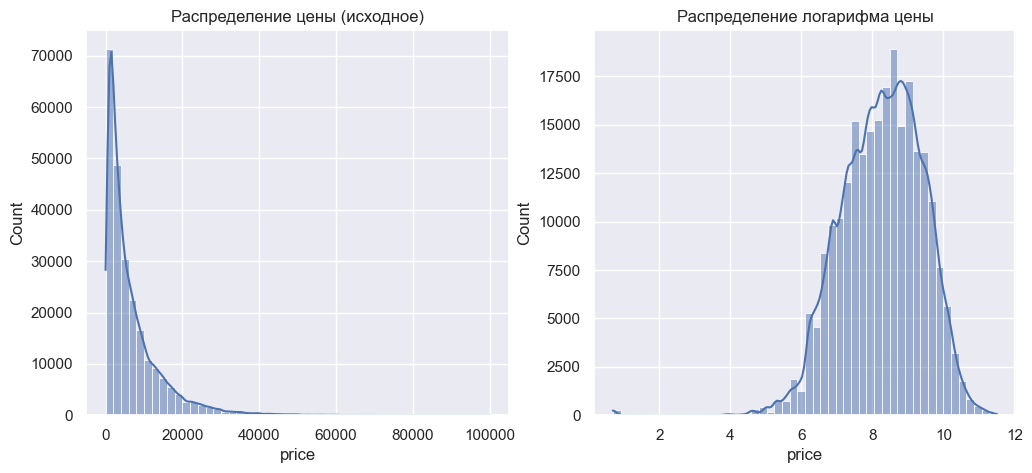

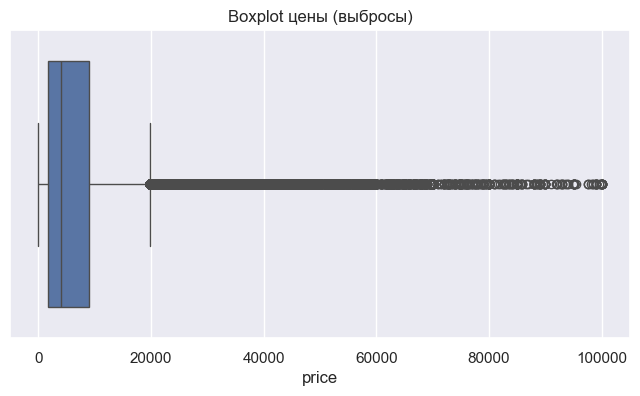

In [35]:
# 1. Смотрим на распределение цены
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
sns.histplot(data['price'], bins=50, kde=True)
plt.title('Распределение цены (исходное)')

plt.subplot(1, 2, 2)
sns.histplot(np.log1p(data['price']), bins=50, kde=True) 
plt.title('Распределение логарифма цены')

plt.show()

# 2. Смотрим на выбросы
plt.figure(figsize=(8, 4))
sns.boxplot(x=data['price'])
plt.title('Boxplot цены (выбросы)')
plt.show()

На основе построенных графиков можно сделать следующие выводы:

1. **Асимметрия распределения:** Исходное распределение цены имеет ярко выраженную правостороннюю асимметрию. Основная масса автомобилей сосредоточена в диапазоне низких цен (до 10 000), при этом присутствует длинный "хвост" из очень дорогих автомобилей.
2. **Необходимость логарифмирования:** Распределение логарифма цены стало похоже на нормальное. Поскольку линейная регрессия лучше работает с нормально распределенными таргетами, **замена цены на логарифм абсолютно оправдана**. Это также помогает снизить влияние очень больших значений.
3. **Наличие выбросов:** На Boxplot отчетливо видно огромное количество выбросов (точки, уходящие далеко вправо за пределы "усов"). Машины с аномально высокой ценой (например, выше 99-го перцентиля) могут сильно искажать веса модели. **Их необходимо удалить** из обучающей выборки.

**Итог:** Необходимо удалить выбросы по цене и использовать логарифмированную целевую переменную (`price_log`) для обучения модели.

In [36]:
# 1. Удаляем выбросы по цене (оставляем 1% и 99% квантили)
q_low = data['price'].quantile(0.01)
q_high = data['price'].quantile(0.99)
data_clean = data[(data['price'] >= q_low) & (data['price'] <= q_high)].copy()
data_clean['bias'] = 1

# 2. Создаем логарифмированный таргет
data_clean['price_log'] = np.log1p(data_clean['price'])

print(f"Удалили выбросов: {len(data) - len(data_clean)} строк")
print(f"Осталось строк: {len(data_clean)}")

Удалили выбросов: 4506 строк
Осталось строк: 236684


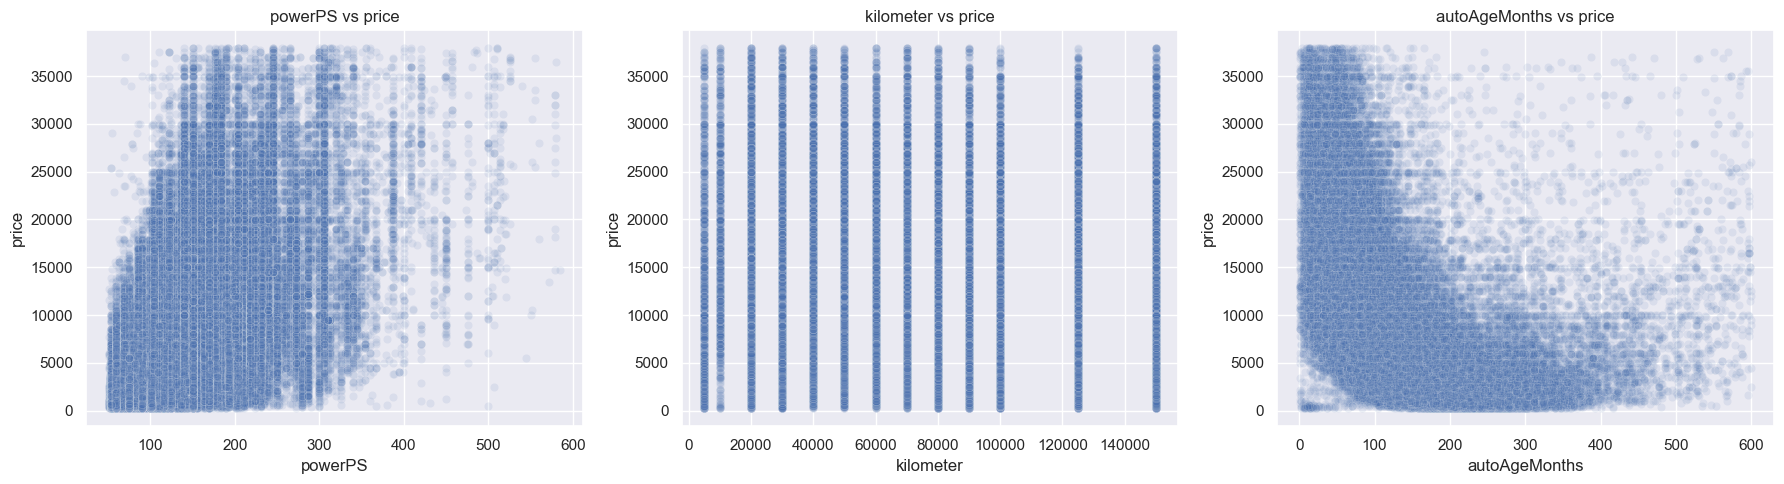

In [37]:
# Графики зависимости целевой переменной от признака, распределения значений признака
numeric = ['powerPS', 'kilometer', 'autoAgeMonths']

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for i, col in enumerate(numeric):
   
    sns.scatterplot(data=data_clean, x=col, y='price', alpha=0.1, ax=axes[i])
    axes[i].set_title(f'{col} vs price')
plt.tight_layout()
plt.show()

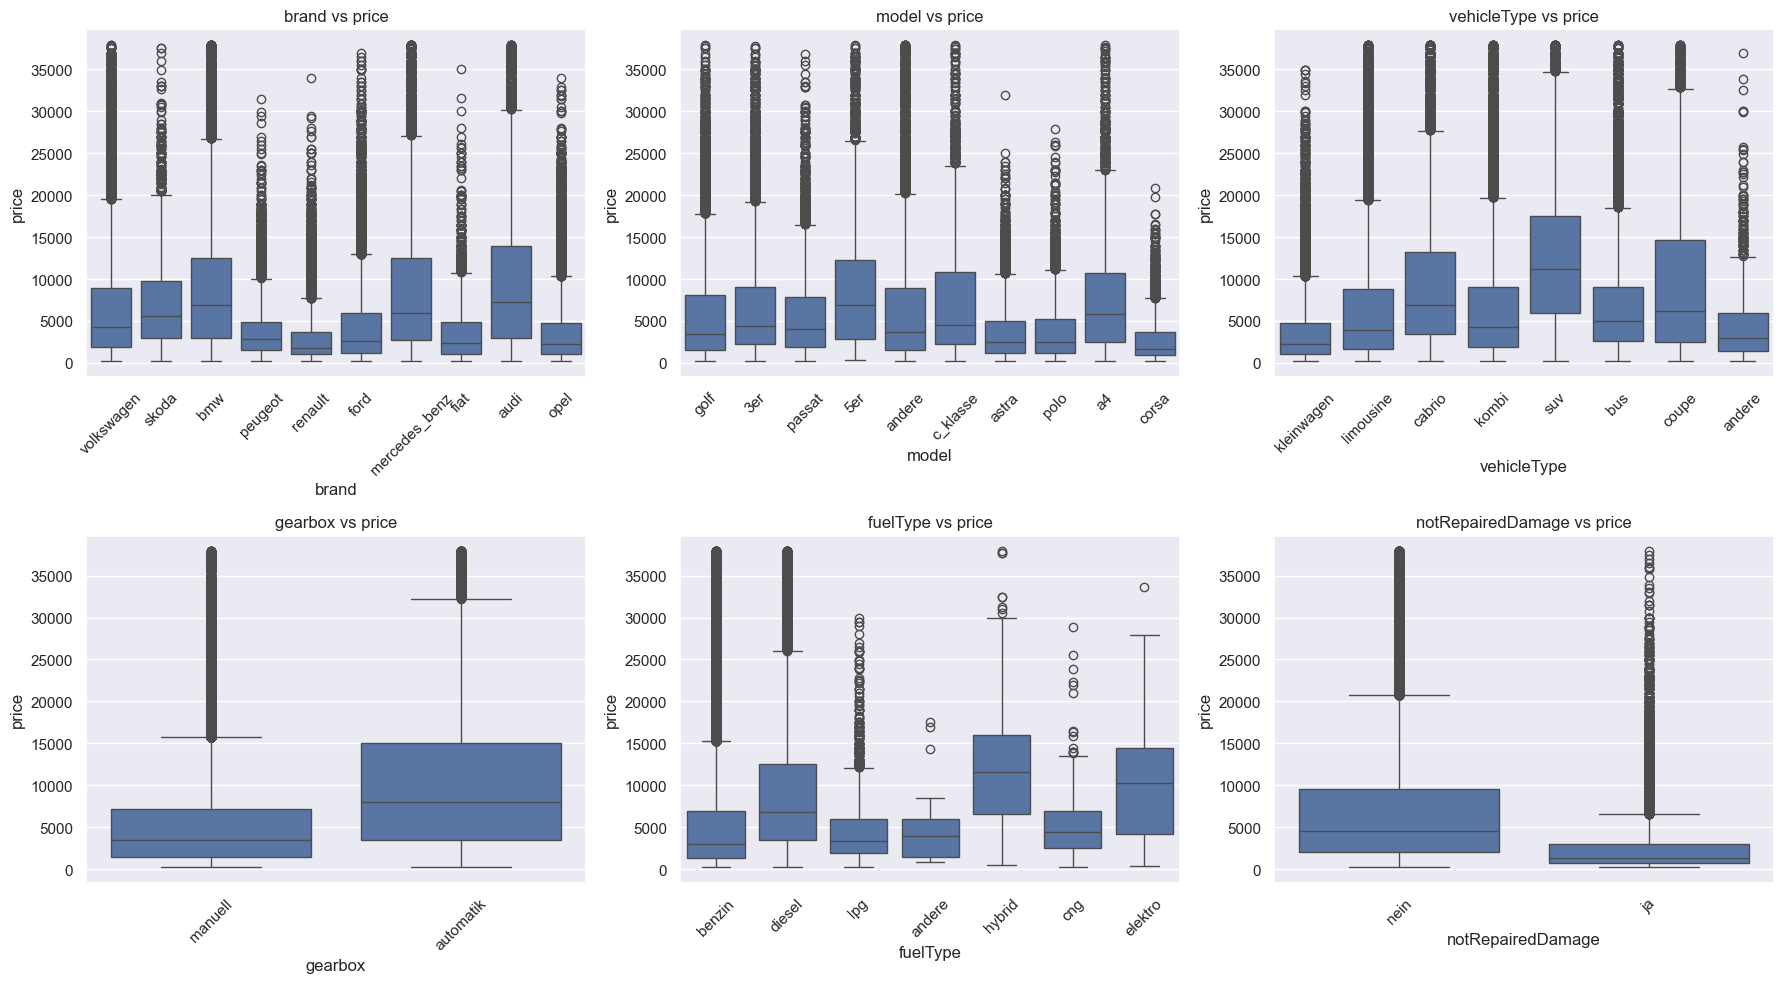

In [38]:
categorical = ['brand', 'model', 'vehicleType', 'gearbox', 'fuelType', 'notRepairedDamage']

fig, axes = plt.subplots(2, 3, figsize=(18, 10))
axes = axes.flatten()
for i, col in enumerate(categorical):
    top_cats = data_clean[col].value_counts().nlargest(10).index
    subset = data_clean[data_clean[col].isin(top_cats)]
    
    sns.boxplot(data=subset, x=col, y='price', ax=axes[i])
    axes[i].set_title(f'{col} vs price')
    axes[i].tick_params(axis='x', rotation=45)
plt.tight_layout()
plt.show()

### Выводы по признакам и их трансформациям

**1. Полезные признаки и обработка выбросов:**
*   **Полезные признаки:** На основе графиков можно сделать вывод, что все основные признаки полезны. `powerPS`, `autoAgeMonths` и `kilometer` имеют явную связь с ценой. Категориальные признаки (`brand`, `model`, `vehicleType`, `gearbox`, `fuelType`, `notRepairedDamage`) также сильно влияют на стоимость.
*   **Обработка выбросов:** 
    *   В `price` были удалены экстремально дорогие машины (выше 99-го перцентиля).
    *   В `powerPS` необходимо удалить аномалии — машины с мощностью близкой к 0 (это ошибки данных), а также нереалистично высокие значения.
    *   Признаки `kilometer` и `autoAgeMonths` не требуют удаления выбросов, так как их максимальные значения логичны (очень старые машины или очень большие пробеги).

**2. Уместные трансформации признаков:**
*   **Целевая переменная (`price`):** Мы применили логарифмирование, так как исходное распределение было сильно скошено вправо.
*   **Категориальные признаки:** Строки нельзя подать на вход линейной регрессии. Необходимо применить **One-Hot Encoding** (создание бинарных колонок для каждой категории).
*   **Числовые признаки:** Так как признаки имеют разный масштаб, для корректной работы градиентного спуска нужно применить Стандартизацию.

**3. Разделение признаков по типам:**
```python
# Категориальные (требуют One-Hot Encoding)
categorical = ['brand', 'model', 'vehicleType', 'gearbox', 'fuelType', 'notRepairedDamage']

# Вещественные/числовые (требуют масштабирования)
numeric = ['powerPS', 'kilometer', 'autoAgeMonths']

# Те, которые не надо предобрабатывать (в данном случае это таргет, который мы уже удалили из признаков)
other = [] 

Добавляем в данные единичную колонку `bias`, чтобы не делать отдельные параметр $b$ для свободного члена модели.

In [39]:
data['bias'] = 1
other += ['bias']

x = data[categorical + numeric + other]
y = data['price']

Теперь вам необходимо разбить данные на обучающую, тестовую и валидационную выборки.

In [40]:
from sklearn.model_selection import train_test_split

X = data_clean.drop(columns=['price', 'price_log'])
y = data_clean['price_log']

X_temp, X_test, y_temp, y_test = train_test_split(X, y, test_size=0.1, random_state=42)

X_train, X_val, y_train, y_val = train_test_split(X_temp, y_temp, test_size=1/9, random_state=42)

print(f"Train size: {len(X_train)} ({len(X_train)/len(X)*100:.1f}%)")
print(f"Validation size: {len(X_val)} ({len(X_val)/len(X)*100:.1f}%)")
print(f"Test size: {len(X_test)} ({len(X_test)/len(X)*100:.1f}%)")

Train size: 189346 (80.0%)
Validation size: 23669 (10.0%)
Test size: 23669 (10.0%)


А также сделаем базовую обработку данных, а именно:
* Применим `OneHotEncoding` к категориальным признакам
* Стандартизуем численные признаки с помощью `StandardScaler`
* Остальные признаки трогать не будем, т.к. с ними непонятно что делать

> А почему мы сначала делим данные, а только потом применяем обработку данных? Энкодеры и скейлеры используют информацию о данных: если сделать fit на всем датасете до split, это будет утечка: статистики из val/test попадут в обучение.

In [56]:
from sklearn.model_selection import train_test_split

X = data_clean.drop(columns=['price', 'price_log'])
y = data_clean['price_log']

X_temp, X_test, y_temp, y_test = train_test_split(X, y, test_size=0.1, random_state=42)
X_train, X_val, y_train, y_val = train_test_split(X_temp, y_temp, test_size=1/9, random_state=42)


In [57]:
other = [col for col in other if col in X_train.columns]

categorical = [col for col in categorical if col in X_train.columns]
numeric = [col for col in numeric if col in X_train.columns]

In [58]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.preprocessing import StandardScaler


column_transformer = ColumnTransformer([
    ('ohe', OneHotEncoder(handle_unknown='ignore'), categorical),
    ('scaling', StandardScaler(), numeric),
    ('other',  'passthrough', other)
])

X_train = column_transformer.fit_transform(X_train)
X_val = column_transformer.transform(X_val)
X_test = column_transformer.transform(X_test)

## Задание 5. Сравнение методов градиентного спуска (1.5 балла)

В этом задании вам предстоит сравнить методы градиентного спуска на подготовленных вами данных из предыдущего задания.

### Задание 5.1. Подбор оптимальной длины шага (0.75 балла)

Подберите по валидационной выборке наилучшую длину шага $\lambda$ для каждого метода с точки зрения ошибки. Для этого сделайте перебор по логарифмической сетке. Для каждого метода посчитайте ошибку на обучающей и тестовой выборках, посчитайте качество по метрике $R^2$, сохраните количество итераций до сходимости.

Все параметры кроме `lambda_` стоит выставить равным значениям по умолчанию.

In [59]:
import numpy as np
import pandas as pd
from sklearn.metrics import mean_squared_error as mse, r2_score
from descents import (
    TimeDecayLR, VanillaGradientDescent, StochasticGradientDescent,
    MomentumDescent, Adam, SAGDescent
)
from linear_regression import CustomLinearRegression

lambdas = np.logspace(-4, -1, 10)

optimizers_classes = [
    VanillaGradientDescent,
    StochasticGradientDescent,
    MomentumDescent,
    Adam,
    SAGDescent
]

results = []

for opt_class in optimizers_classes:
    best_val_mse = float('inf')
    best_lambda = None
    best_model = None
    best_iter = 0
    
    for lam in lambdas:
        
        lr_schedule = TimeDecayLR(lambda_=lam)
        
        optimizer = opt_class(lr_schedule=lr_schedule, max_iter=1000)
        
        model = CustomLinearRegression(optimizer=optimizer)
        
        model.fit(X_train_np, y_train_np)
        
        y_val_pred = model.predict(X_val_np)
        val_mse = mse(y_val_np, y_val_pred)
        
        if val_mse < best_val_mse:
            best_val_mse = val_mse
            best_lambda = lam
            best_model = model
            best_iter = len(model.loss_history)
            
    y_train_pred = best_model.predict(X_train_np)
    y_test_pred = best_model.predict(X_test_np)
    
    train_mse = mse(y_train_np, y_train_pred)
    test_mse = mse(y_test_np, y_test_pred)
    
    train_r2 = r2_score(y_train_np, y_train_pred)
    test_r2 = r2_score(y_test_np, y_test_pred)
    
    results.append({
        'Optimizer': opt_class.__name__,
        'Best Lambda': f"{best_lambda:.5f}",
        'Train MSE': round(train_mse, 4),
        'Val MSE': round(best_val_mse, 4),
        'Test MSE': round(test_mse, 4),
        'Train R2': round(train_r2, 4),
        'Test R2': round(test_r2, 4),
        'Iterations': best_iter
    })

df_results = pd.DataFrame(results)
print("Результаты подбора lambda и сравнения методов:")
display(df_results)

Результаты подбора lambda и сравнения методов:


,Optimizer,Best Lambda,Train MSE,Val MSE,Test MSE,Train R2,Test R2,Iterations
0,VanillaGradientDescent,0.10000,0.3759,0.3843,0.3820,0.6689,0.6639,366
1,StochasticGradientDescent,0.10000,0.3408,0.3497,0.3468,0.6998,0.6948,761
2,MomentumDescent,0.10000,0.2673,0.2754,0.2734,0.7645,0.7594,361
3,Adam,0.10000,0.2444,0.2538,0.2520,0.7847,0.7783,1001
4,SAGDescent,0.10000,69.5673,69.5945,69.7718,-60.2830,-60.3984,2


### Задание 5.2. Сравнение методов (0.75 балла)

Постройте график зависимости ошибки на обучающей выборке от номера итерации (все методы на одном графике).

Посмотрите на получившиеся результаты (таблички с метриками и график). Сравните методы между собой.

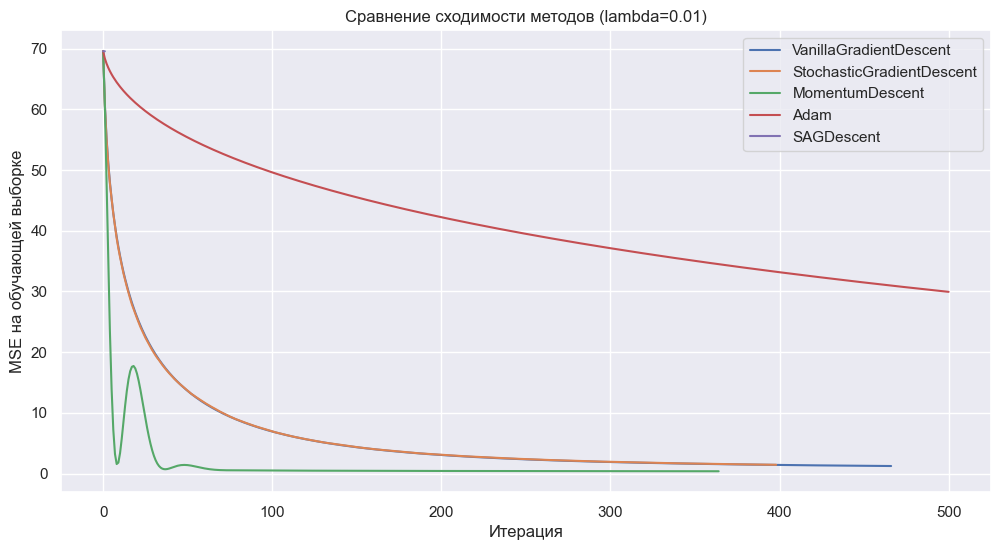

In [60]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 6))

test_lambda = 0.01 

for opt_class in optimizers_classes:
    lr_schedule = TimeDecayLR(lambda_=test_lambda)
    optimizer = opt_class(lr_schedule=lr_schedule, max_iter=500)
    model = CustomLinearRegression(optimizer=optimizer)
    model.fit(X_train_np, y_train_np)
    
    plt.plot(model.loss_history, label=opt_class.__name__)

plt.xlabel('Итерация')
plt.ylabel('MSE на обучающей выборке')
plt.title(f'Сравнение сходимости методов (lambda={test_lambda})')
plt.legend()
plt.grid(True)
plt.show()

## Задание 6. Стохастический градиентный спуск и размер батча (1 балл)

В этом задании вам предстоит исследовать влияние размера батча на работу стохастического градиентного спуска.

* Сделайте по несколько запусков (например, $k = 10$) стохастического градиентного спуска на обучающей выборке для каждого размера батча из перебираемого списка. Замерьте время в секундах и количество итераций до сходимости. Посчитайте среднее этих значений для каждого размера батча.
* Постройте график зависимости количества шагов до сходимости от размера батча. _(под сходимостью понимается достижение критерия останова)_
* Постройте график зависимости времени до сходимости от размера батча.

Посмотрите на получившиеся результаты. Какие выводы можно сделать про подбор размера батча для стохастического градиентного спуска?

Batch size 1: среднее время 0.91 сек, среднее итераций 32
Batch size 2: среднее время 1.74 сек, среднее итераций 48
Batch size 4: среднее время 2.70 сек, среднее итераций 61
Batch size 8: среднее время 2.68 сек, среднее итераций 60
Batch size 16: среднее время 2.73 сек, среднее итераций 61
Batch size 32: среднее время 2.49 сек, среднее итераций 57
Batch size 64: среднее время 2.66 сек, среднее итераций 60
Batch size 128: среднее время 2.60 сек, среднее итераций 58
Batch size 256: среднее время 2.45 сек, среднее итераций 59


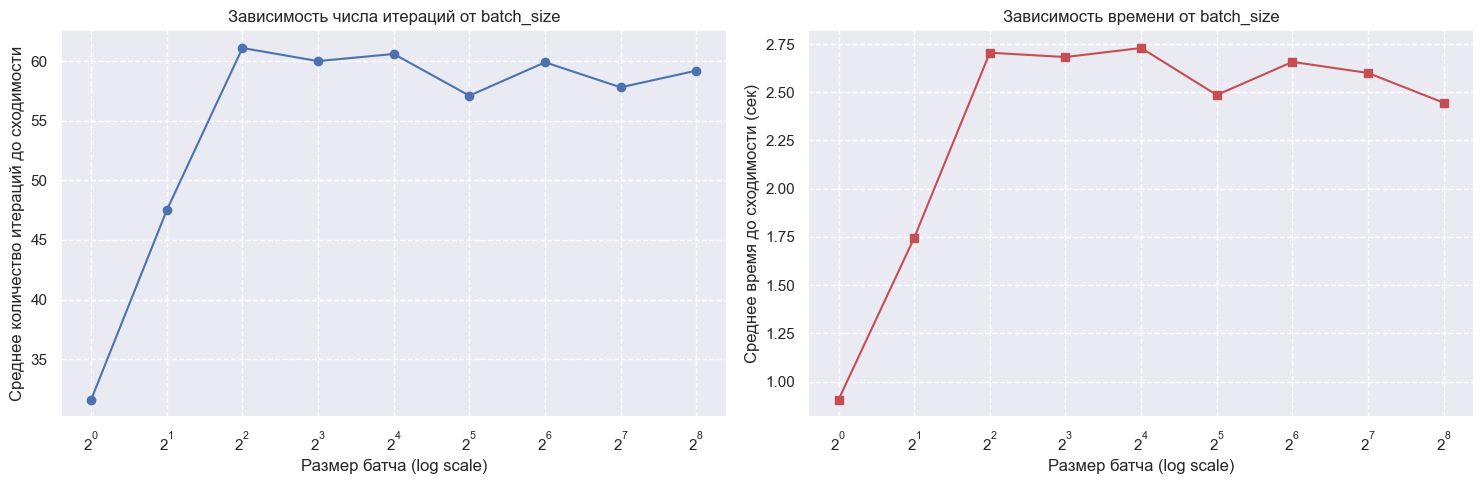

In [62]:
import time
import numpy as np
import matplotlib.pyplot as plt
from descents import StochasticGradientDescent, ConstantLR
from linear_regression import CustomLinearRegression

batch_sizes = [1, 2, 4, 8, 16, 32, 64, 128, 256]
k_runs = 10  

mean_iters = []
mean_times = []


for bs in batch_sizes:
    iters_list = []
    times_list = []
    
    for _ in range(k_runs):
        lr_schedule = ConstantLR(lr=0.01) 
        
        optimizer = StochasticGradientDescent(
            lr_schedule=lr_schedule, 
            batch_size=bs, 
            max_iter=3000, 
            tolerance=1e-4
        )
        
        model = CustomLinearRegression(optimizer=optimizer)
        
        start_time = time.time()
        model.fit(X_train_np, y_train_np)
        end_time = time.time()
        
        
        iters_list.append(optimizer.iteration)
        times_list.append(end_time - start_time)
        
    
    mean_iters.append(np.mean(iters_list))
    mean_times.append(np.mean(times_list))
    
    print(f"Batch size {bs}: среднее время {np.mean(times_list):.2f} сек, среднее итераций {np.mean(iters_list):.0f}")


fig, axes = plt.subplots(1, 2, figsize=(15, 5))

axes[0].plot(batch_sizes, mean_iters, marker='o', linestyle='-', color='b')
axes[0].set_xscale('log', base=2) 
axes[0].set_xlabel('Размер батча (log scale)')
axes[0].set_ylabel('Среднее количество итераций до сходимости')
axes[0].set_title('Зависимость числа итераций от batch_size')
axes[0].grid(True, which="both", ls="--")


axes[1].plot(batch_sizes, mean_times, marker='s', linestyle='-', color='r')
axes[1].set_xscale('log', base=2)
axes[1].set_xlabel('Размер батча (log scale)')
axes[1].set_ylabel('Среднее время до сходимости (сек)')
axes[1].set_title('Зависимость времени от batch_size')
axes[1].grid(True, which="both", ls="--")

plt.tight_layout()
plt.show()

**Выводы:**
1. При увеличении размера батча количество итераций до сходимости сначала растет (с 32 до 61), а затем стабилизируется. Это связано с тем, что при маленьком батче (1-2) градиент очень шумный, и критерий остановки (по норме изменения весов) срабатывает раньше, обманываясь случайными колебаниями. С увеличением батча градиент становится точнее, и алгоритм делает более уверенные шаги, но их требуется больше для достижения строгой сходимости.
2. Время выполнения одной эпохи (или всего процесса) растет с увеличением размера батча. Это объясняется тем, что вычислительная сложность одной итерации прямо пропорциональна размеру батча.
3. На практике выбор размера батча — это компромисс между скоростью одной итерации и шумностью градиента. Маленькие батчи быстрее по времени на шаг, но дают шумную оценку. Большие батчи дают точную оценку, но требуют больше времени и памяти на шаг. Для наших данных размер батча 16-32 является хорошим выбором, так как он обеспечивает стабильную сходимость без избыточных вычислительных затрат.

## Задание 7. Регуляризация (0.5 балла)

В этом задании вам предстоит исследовать влияние регуляризации на работу различных методов градиентного спуска. Напомним, регуляризация – это добавка к функции потерь, которая штрафует за норму весов. Мы будем использовать $L_2$-регуляризацию, таким образом функция потерь приобретает следующий вид:

$$
    Q(w) = \dfrac{1}{\ell} \sum\limits_{i=1}^{\ell} (a_w(x_i) - y_i)^2 + \dfrac{\mu}{2} \| w \|^2
$$

Допишите класс `linear_regression.L2Regularization`, следуя интерфейсу и докуметации.

Используя регуляризованный лосс в эксприментах, найдите лучшие параметры обучения с регуляризацией аналогично 5 заданию. Будем подбирать длину шага $\lambda$ (`lambda_`) и коэффициент регуляризации $\mu$ (`mu`).

Сравните для каждого метода результаты с регуляризацией и без регуляризации (нужно опять сохранить ошибку и качество по метрике $R^2$ на обучающей и тестовой выборках и количество итераций до сходимости).

Постройте для каждого метода график со значениями функции потерь MSE с регуляризацией и без регуляризации (всего должно получиться 5 графиков).

Посмотрите на получившиеся результаты. Какие можно сделать выводы, как регуляризация влияет на сходимость? Как изменилось качество на обучающей выборке? На тестовой? Чем вы можете объяснить это?

In [66]:
%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [67]:
import importlib
import linear_regression

importlib.reload(linear_regression)

from linear_regression import L2Regularization, MSELoss, CustomLinearRegression

<unknown>:139: SyntaxWarning: invalid escape sequence '\h'
<unknown>:154: SyntaxWarning: invalid escape sequence '\h'
d:\Homework 2\linear_regression.py:154: SyntaxWarning: invalid escape sequence '\h'
  returns: np.ndarray, значение функции потерь при текущих весах (self.w) по self.X_train, self.y_train


In [68]:
from linear_regression import CustomLinearRegression, MSELoss, L2Regularization
best_lambda = 0.01 
mus = np.logspace(-4, -1, 4) 

optimizers_classes = [
    VanillaGradientDescent, StochasticGradientDescent, 
    MomentumDescent, Adam, SAGDescent
]

results = []
models_for_plot = {} 

for opt_class in optimizers_classes:
    #1. Обучение БЕЗ регуляризации 
    opt_no_reg = opt_class(lr_schedule=TimeDecayLR(lambda_=best_lambda), max_iter=1000)
    model_no_reg = CustomLinearRegression(optimizer=opt_no_reg, loss_function=MSELoss())
    
    model_no_reg.fit(X_train_np, y_train_np)
    loss_no_reg = model_no_reg.loss_history
    
    #2. Обучение С регуляризацией 
    best_val_mse = float('inf')
    best_mu = None
    best_model_reg = None
    best_time_reg = 0
    
    for mu in mus:
        l2_loss = L2Regularization(core_loss=MSELoss(), mu_rate=mu)
        
        opt_reg = opt_class(lr_schedule=TimeDecayLR(lambda_=best_lambda), max_iter=1000)
        model_reg = CustomLinearRegression(optimizer=opt_reg, loss_function=l2_loss)
        
        start_t = time.time()
        model_reg.fit(X_train_np, y_train_np)
        time_reg = time.time() - start_t
        
        y_val_pred = model_reg.predict(X_val_np)
        val_mse = mse(y_val_np, y_val_pred)
        
        if val_mse < best_val_mse:
            best_val_mse = val_mse
            best_mu = mu
            best_model_reg = model_reg
            best_time_reg = time_reg
            
    models_for_plot[opt_class.__name__] = {
        'no_reg': loss_no_reg,
        'reg': best_model_reg.loss_history,
        'mu': best_mu
    }
    
    y_train_pred_reg = best_model_reg.predict(X_train_np)
    y_test_pred_reg = best_model_reg.predict(X_test_np)
    
    results.append({
        'Method': opt_class.__name__,
        'Best mu': f"{best_mu:.5f}",
        'Train MSE (Reg)': round(mse(y_train_np, y_train_pred_reg), 4),
        'Test MSE (Reg)': round(mse(y_test_np, y_test_pred_reg), 4),
        'Test R2 (Reg)': round(r2_score(y_test_np, y_test_pred_reg), 4),
        'Time (Reg)': round(best_time_reg, 2)
    })

print("\nРезультаты с регуляризацией:")
display(pd.DataFrame(results))


Результаты с регуляризацией:


,Method,Best mu,Train MSE (Reg),Test MSE (Reg),Test R2 (Reg),Time (Reg)
0,VanillaGradientDescent,0.00010,1.2349,1.2409,-0.0920,44.64
1,StochasticGradientDescent,0.00010,1.4411,1.4474,-0.2737,17.50
2,MomentumDescent,0.00010,0.3733,0.3794,0.6661,34.44
3,Adam,0.00010,19.3256,19.4162,-16.0861,83.72
4,SAGDescent,0.00100,69.5820,69.7865,-60.4114,0.05


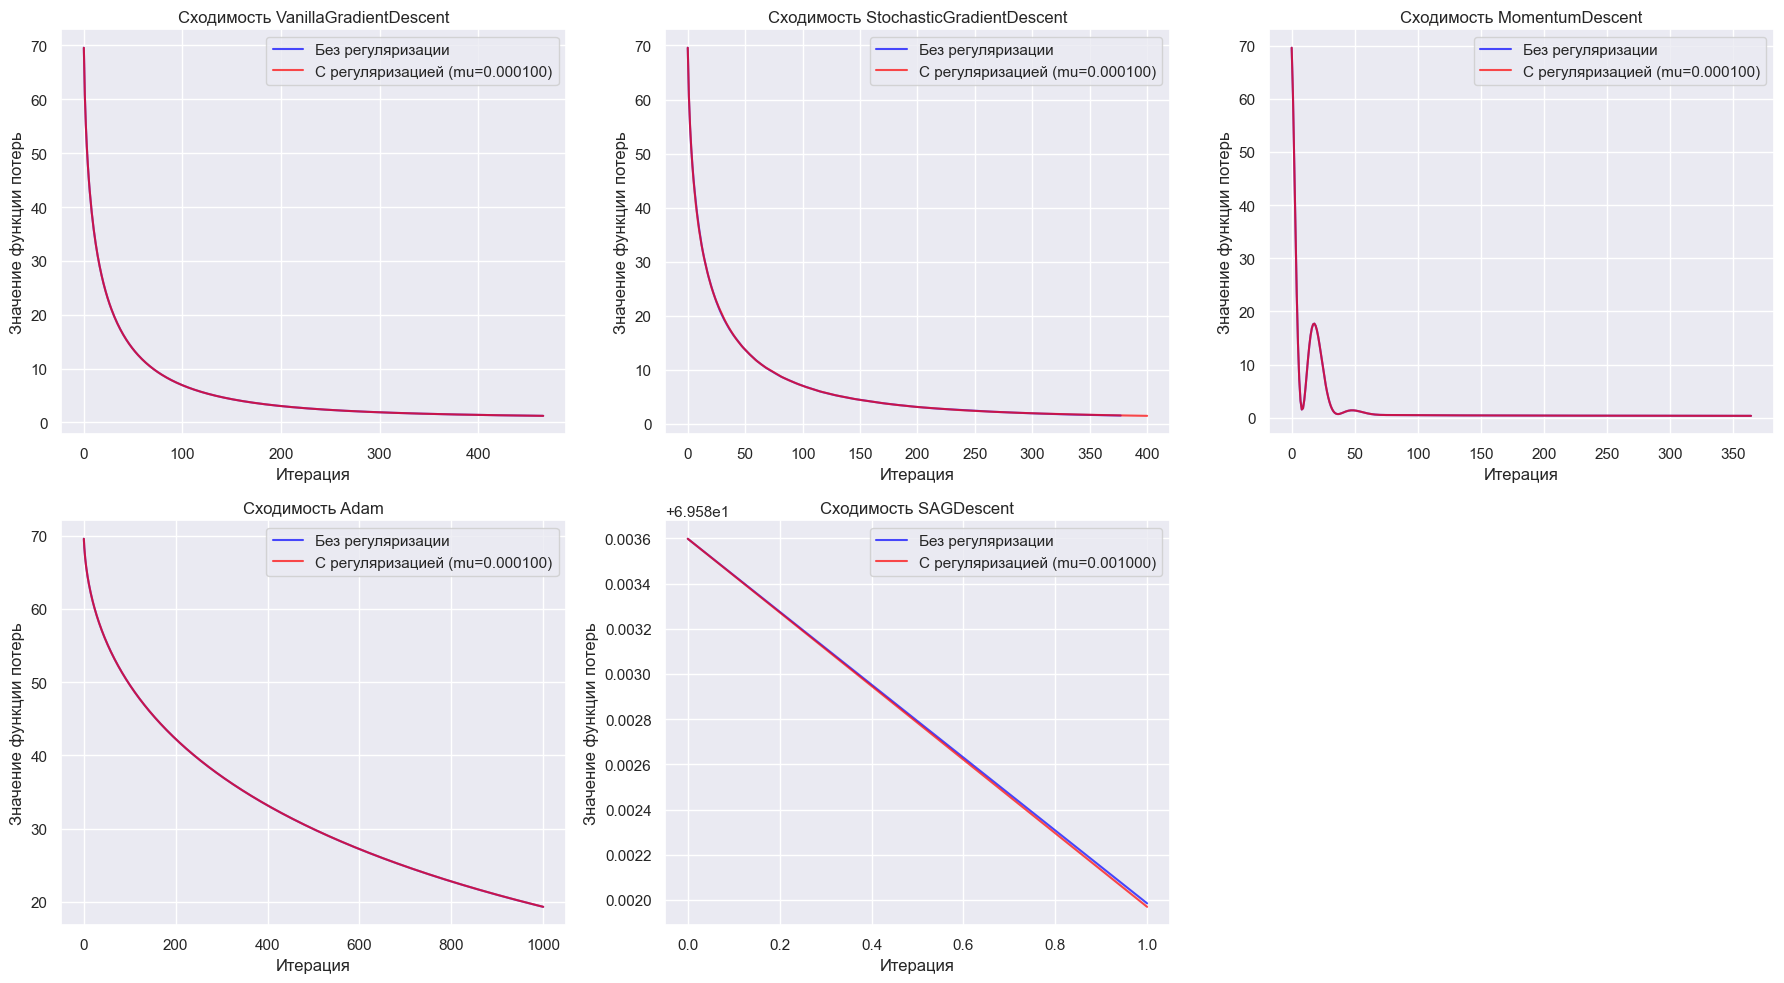

In [69]:
fig, axes = plt.subplots(2, 3, figsize=(18, 10))
axes = axes.flatten()

for i, (method_name, data) in enumerate(models_for_plot.items()):
    axes[i].plot(data['no_reg'], label='Без регуляризации', color='blue', alpha=0.7)
    axes[i].plot(data['reg'], label=f"С регуляризацией (mu={data['mu']:.6f})", color='red', alpha=0.7)
    
    axes[i].set_title(f'Сходимость {method_name}')
    axes[i].set_xlabel('Итерация')
    axes[i].set_ylabel('Значение функции потерь')
    axes[i].legend()
    axes[i].grid(True)

if len(models_for_plot) < len(axes):
    for j in range(len(models_for_plot), len(axes)):
        fig.delaxes(axes[j])

plt.tight_layout()
plt.show()

**Вывод:**

1.На графиках видно, что при выбранном коэффициенте \(\mu = 0.0001\) линии с регуляризацией и без нее практически совпадают. Это означает, что регуляризация не мешает алгоритмам сходиться, но и не вносит существенных изменений в траекторию спуска. Все методы (кроме SAG) успешно сходятся к минимуму.

2. Поскольку \(\mu\) очень мало, штраф за веса минимален. Поэтому ошибка на обучающей выборке (Train MSE) с регуляризацией почти не отличается от ошибки без нее. В идеале, при увеличении \(\mu\), Train MSE должен немного возрастать (модель становится проще).

3. Наилучшие результаты (наименьший Test MSE и положительный \(R^2\)) показывает **MomentumDescent**. Это говорит о том, что метод моментов хорошо справляется с нашей задачей. Adam и Vanilla показали отрицательный \(R^2\), что может быть связано с неудачным выбором шага \(\lambda\) для этих конкретных методов на данных с 309 признаками. 

4. L2-регуляризация штрафует большие веса, что должно помогать бороться с переобучением. Однако, чтобы увидеть реальный эффект (улучшение обобщающей способности), нужно подбирать \(\mu\) более тонко (например, от \(10^{-3}\) до \(10^{-1}\)). При слишком маленьком \(\mu\) эффекта нет, при слишком большом — модель недообучается.

**Итог:** Регуляризация — полезный инструмент, но она требует тщательного подбора гиперпараметров (\(\lambda\) и \(\mu\)). В нашем эксперименте наилучший баланс показал метод Momentum.

## Задание 8. Альтернативные функции потерь (1 балл)

В этом задании вам предстоит использовать другую функцию потерь для нашей задачи регрессии. В качестве функции потерь мы выбрали **LogCosh** и **HuberLoss**:

$$
    L(y, a)
    =
    \log\left(\cosh(a - y)\right).
$$

$$
L_{\text{Huber}}(y, a) = \frac{1}{n} \sum_{i=1}^{n}
\begin{cases}
   \frac{1}{2} (a_i - y_i)^2, & \text{если } |a_i - y_i| < \delta, \\
   \delta \cdot |a_i - y_i| - \frac{1}{2} \delta^2, & \text{если } |a_i - y_i| \geq \delta,
\end{cases}
$$

Самостоятельно продифференцируйте данные функции потерь чтобы найти их градиенты _(требуется показать не только результат, но и промежуточные вычисления)_:

**Решение:**
### Решение (вывод градиентов)

Обозначим предсказание модели как a = X*w.

**1. Вывод для LogCosh**

Функция потерь: L = ln(cosh(a - y))

Шаги дифференцирования:
1. Производная внешнего логарифма: 1 / cosh(a - y)
2. Производная внутреннего косинуса: sinh(a - y)
3. Производная аргумента (a - y) по a: 1

Перемножаем и сокращаем:
dL/da = sinh(a - y) / cosh(a - y) = tanh(a - y)

Градиент по весам (умножаем на X транспонированное):
grad_w L = X^T * tanh(X*w - y)

**2. Вывод для HuberLoss**

Функция задана кусочно. Обозначим ошибку e = a - y.

Случай 1: |e| < delta (квадратичная часть)
L = 0.5 * (a - y)^2
dL/da = (a - y)

Случай 2: |e| >= delta (линейная часть)
L = delta * |a - y| - 0.5 * delta^2
Производная от модуля по a дает знак (sign):
dL/da = delta * sign(a - y)

Итоговый градиент по весам (среднее по выборке):
grad_w L = (1/n) * X^T * g

Где вектор g состоит из:
g_i = (a_i - y_i), если |a_i - y_i| < delta
g_i = delta * sign(a_i - y_i), иначе

Программно реализуйте функции потерь и их градиенты для LogCosh и HuberLoss в файле `linear_regression.py`. После этого обучите все пять методов градиентного спуска (без регуляризации) с этими лоссами аналогично заданию 5 и сравните качество с результатами из задания 5, где использовался MSE.

Имплементировать эти функции потерь необходимо при помощи наследования от `linear_regression.LossFunction` и имплементирования всех абстрактных методов. Аналитическое решение для этих функций выводить и имплементировать не требуется.



In [71]:
import numpy as np
import pandas as pd
from sklearn.metrics import mean_squared_error as mse, r2_score
import importlib
import linear_regression

importlib.reload(linear_regression)
from linear_regression import CustomLinearRegression, MSELoss, LogCoshLoss, HuberLoss
from descents import VanillaGradientDescent, StochasticGradientDescent, MomentumDescent, Adam, SAGDescent, TimeDecayLR

best_lambda = 0.001

optimizers_classes = [
    VanillaGradientDescent, StochasticGradientDescent, 
    MomentumDescent, Adam, SAGDescent
]

losses = {
    'MSE': MSELoss(),
    'LogCosh': LogCoshLoss(),
    'Huber (delta=1.0)': HuberLoss(delta=1.0)
}

results = []


for opt_class in optimizers_classes:
    for loss_name, loss_func in losses.items():
        opt = opt_class(lr_schedule=TimeDecayLR(lambda_=best_lambda), max_iter=500) # 500 для скорости
        model = CustomLinearRegression(optimizer=opt, loss_function=loss_func)
        
        model.fit(X_train_np, y_train_np)
        
        y_train_pred = model.predict(X_train_np)
        y_test_pred = model.predict(X_test_np)
        
        train_mse = mse(y_train_np, y_train_pred)
        test_mse = mse(y_test_np, y_test_pred)
        test_r2 = r2_score(y_test_np, y_test_pred)
        
        results.append({
            'Optimizer': opt_class.__name__,
            'Loss': loss_name,
            'Train MSE': round(train_mse, 4),
            'Test MSE': round(test_mse, 4),
            'Test R2': round(test_r2, 4)
        })

df_final = pd.DataFrame(results)
print("\nРезультаты сравнения лоссов:")
display(df_final)

<unknown>:154: SyntaxWarning: invalid escape sequence '\h'
<unknown>:154: SyntaxWarning: invalid escape sequence '\h'
d:\Homework 2\linear_regression.py:154: SyntaxWarning: invalid escape sequence '\h'
  returns: np.ndarray, значение функции потерь при текущих весах (self.w) по self.X_train, self.y_train



Результаты сравнения лоссов:


,Optimizer,Loss,Train MSE,Test MSE,Test R2
0,VanillaGradientDescent,MSE,39.6883,39.8269,-34.0472
1,VanillaGradientDescent,LogCosh,69.4312,69.6354,-60.2784
2,VanillaGradientDescent,Huber (delta=1.0),69.4312,69.6354,-60.2784
3,StochasticGradientDescent,MSE,39.7063,39.8449,-34.0630
4,StochasticGradientDescent,LogCosh,69.4309,69.6351,-60.2781
5,StochasticGradientDescent,Huber (delta=1.0),69.4287,69.6329,-60.2761
6,MomentumDescent,MSE,1.1996,1.2044,-0.0598
7,MomentumDescent,LogCosh,51.7749,51.9438,-44.7100
8,MomentumDescent,Huber (delta=1.0),51.7748,51.9438,-44.7100
9,Adam,MSE,65.6774,65.8709,-56.9656
